#TakarMobil: Exploratory Data Analysis (EDA)
**Proyek Akhir Machine Learning - Semester 5**  
*TakarMobil: Sistem Estimasi Rentang Harga & Analisis Faktor Penentu Harga Mobil Bekas*

---

### 📚 Sumber Data & Verifikasi Dataset:
- **Judul Publikasi:** *Implementation of Machine Learning Algorithms to Predict Used Car Prices in Indonesia*
- **Repositori & DOI Resmi:** [Zenodo Record 17548894](https://zenodo.org/records/17548894) (`DOI: 10.5281/zenodo.17548894`, publikasi 7 November 2025)
- **Pembuat Dataset:** Ivory Thania (Binus University)
- **Lisensi:** Creative Commons Attribution 4.0 International (**CC-BY-4.0**)
- **Periode & Metode Pengambilan Data:** Hasil *web scraping* menggunakan Python (**BeautifulSoup** dan **Selenium**) atas iklan publik di **OLX** dan **Mobil123** pada periode **Mei–Oktober 2025**. Berkas mentah `Data Scraping.xlsx` terdiri dari **17.670 baris** dan **16 kolom**.

### 🎯 Tujuan Tahap EDA:
1. Memahami struktur, dimensi, kamus variabel lengkap (Bab 4 Ketentuan), dan tipe data mentah.
2. Mengidentifikasi kualitas data: *missing values*, duplikasi, anomali label/format, serta relevansi *class imbalance* pada kasus regresi.
3. Menganalisis statistik deskriptif (baik kondisi mentah maupun subset bersih 5 merek utama) beserta distribusi target harga ($\log(1 + \text{Harga})$) dan fitur numerik (`KM_Num`, `Tahun_Num`, `Usia_Mobil`).
4. Menganalisis sebaran fitur kategorikal (5 merek utama hasil konsolidasi, transmisi, bahan bakar, dan wilayah Jabodetabek).
5. Menganalisis bukti empiris antar-platform (`OLX` vs `Mobil123`): pola *missing KM* terhadap harga, fragmentasi nama model, serta sebaran harga per merek.
6. Mendeteksi outlier per merek (Boxplot & IQR), mengkaji korelasi Pearson, serta menyusun rekomendasi terstruktur untuk Phase 3 (Preprocessing).

## 1. Import Library & Konfigurasi Lingkungan
Memuat pustaka manipulasi data (`pandas`, `numpy`), visualisasi (`matplotlib`, `seaborn`), dan regex (`re`) untuk pemeriksaan kualitas string.

In [1]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Semua library berhasil dimuat!")

Semua library berhasil dimuat!


## 2. Pemuatan Dataset Mentah (Raw Data)
Dataset dimuat langsung dari `../data/raw/Data Scraping.xlsx` (`17.670` baris iklan mobil bekas dari **OLX** dan **Mobil123**, Mei–Oktober 2025).

In [2]:
candidate_paths = [
    "data/raw/Data Scraping.xlsx",
    "../data/raw/Data Scraping.xlsx",
    "Data Scraping.xlsx"
]
file_path = next((p for p in candidate_paths if os.path.exists(p)), None)
if file_path is None:
    raise FileNotFoundError("File Data Scraping.xlsx tidak ditemukan!")

print(f"Memuat dataset dari: {file_path}")
df_raw = pd.read_excel(file_path)
print(f"Dimensi Dataset Mentah: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
df_raw.head(3)

Memuat dataset dari: ../data/raw/Data Scraping.xlsx


Dimensi Dataset Mentah: 17670 baris x 16 kolom


,Sumber,URL,Judul,Merek,Model,Varian,Tahun,Kilometer,Transmisi,Warna,Kapasitas Mesin,Bahan Bakar,Tanggal Upload,Lokasi,Tipe Bodi,Harga
0,OLX,https://www.olx.co.id/item/939502279,MERCEDES BENZ A45 AMG 2014 2.0 TURBO AWD PANOR...,Mercedes-Benz,A45 AMG,2.0 Bensin-AT,2014,NaN,Automatic,Putih,NaN,Bensin,07-10-2025,Jakarta Timur,NaN,499.000.000
1,OLX,https://www.olx.co.id/item/939871468,Mercedes Benz Sprinter A415 CDI 2022,Mercedes-Benz,Sprinter,NaN,2021,NaN,Manual,Hitam,NaN,Diesel,17-10-2025,Jakarta Utara,NaN,1.850.000.000
2,OLX,https://www.olx.co.id/item/939450820,[ GARANSI 5TH ] Mercedes Benz Mercy GLC200 GLC...,Mercedes-Benz,GLC200,2.0 AMG Line Bensin-AT,2022,NaN,Automatic,Putih,NaN,Bensin,06-10-2025,Jakarta Barat,NaN,720.000.000


## 3. Struktur Dataset & Kamus Variabel Lengkap (Ketentuan Bab 4)
Pemeriksaan tipe data awal (`df_raw.info()`) diikuti kamus lengkap ke-16 kolom untuk memastikan pemahaman domain setiap atribut sebelum pemodelan.

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 17670 entries, 0 to 17669
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Sumber           17670 non-null  str   
 1   URL              17670 non-null  str   
 2   Judul            17498 non-null  object
 3   Merek            17494 non-null  str   
 4   Model            17494 non-null  str   
 5   Varian           17436 non-null  object
 6   Tahun            17492 non-null  object
 7   Kilometer        13776 non-null  str   
 8   Transmisi        17492 non-null  str   
 9   Warna            17492 non-null  str   
 10  Kapasitas Mesin  12908 non-null  str   
 11  Bahan Bakar      17492 non-null  object
 12  Tanggal Upload   17492 non-null  object
 13  Lokasi           17490 non-null  str   
 14  Tipe Bodi        9323 non-null   str   
 15  Harga            17494 non-null  object
dtypes: object(6), str(10)
memory usage: 4.3+ MB


### 📖 Kamus Variabel (`Data Scraping.xlsx` — 16 Kolom)

| No. | Kolom | Tipe Mentah | Deskripsi / Arti Variabel | Contoh Nilai | Peran di Pipeline |
|---|---|---|---|---|---|
| 1 | `Sumber` | `str` | Platform marketplace sumber iklan (`OLX` atau `Mobil123`). | `OLX`, `Mobil123` | Audit bias platform & fitur analisis EDA (tidak dipakai langsung saat inferensi web) |
| 2 | `URL` | `str` | Tautan unik halaman iklan sumber. | `https://www.olx.co.id/item/...` | Kunci deduplikasi iklan kembar (`drop_duplicates`) |
| 3 | `Judul` | `object/str` | Judul teks iklan yang ditulis penjual/dealer. | `DP MURAH Daihatsu Ayla...` | Audit salah ketik tahun/merek, pemulihan tipe, & deduplikasi |
| 4 | `Merek` | `str` | Nama merek pabrikan kendaraan (pada Mobil123 seri Mercedes terpisah). | `Toyota`, `C-Class` | Dinormalisasi ke **5 merek utama** (`Merek_Clean`) |
| 5 | `Model` | `str` | Nama model/tipe mobil pada platform (`Brio Satya` di OLX vs `Brio` di Mobil123). | `Avanza`, `E300` | Dinormalisasi lintas-platform + keluarga model Mercedes (`Model_Clean`) |
| 6 | `Varian` | `object/str` | Trim/mesin/kode spesifik varian mobil (43 missing di subset bersih). | `1.5 G Bensin-AT`, `AMG Line` | Diekstrak ke fitur trim `Varian_Clean` |
| 7 | `Tahun` | `object` | Tahun produksi kendaraan dalam format string/angka. | `2019`, `2022` | Diparsing menjadi `Tahun_Num` dan diturunkan ke `Usia_Mobil` (`2025 - Tahun`) |
| 8 | `Kilometer` | `str` | Jarak tempuh odometer berformat rentang OLX (`50.000-55.000 km`) atau `'K'` Mobil123 (`10 - 15K km`). | `10 - 15K km` | Diparsing ke `KM_Num`, dibentuk indikator `KM_hilang`, lalu diimputasi pasca-split ke `KM_Clean` |
| 9 | `Transmisi` | `str` | Jenis sistem transmisi kendaraan. | `Automatic`, `Manual` | Diseragamkan ke `Transmisi_Clean` (`Automatic` / `Manual`) |
| 10 | `Warna` | `str` | Warna eksterior mobil. | `Hitam`, `Putih` | Pembentuk kunci identifikasi iklan kembar `dup_group` tanpa harga |
| 11 | `Kapasitas Mesin` | `str` | Kapasitas silinder/cc kendaraan (26,95% kosong). | `1.500 cc` | **Dieliminasi** ( kekosongan tinggi & informasi terwakili oleh `Model_Clean` + `Varian_Clean`) |
| 12 | `Bahan Bakar` | `object/str` | Jenis sumber energi kendaraan (`Bensin`, `Petrol`, `Diesel`, `Hybrid`, `Listrik`). | `Bensin`, `Petrol` | Diseragamkan ke `Bahan_Bakar_Clean` (`Bensin`, `Diesel`, `Hybrid`) |
| 13 | `Tanggal Upload` | `object/str` | Tanggal pengunggahan iklan saat di-scrape. | `2025-10-12` | Konteks periode data; **dieliminasi** dari fitur prediksi |
| 14 | `Lokasi` | `str` | Kota/kecamatan iklan, termasuk format promo Mobil123 (`Pondok Indah, 3% off`). | `Jakarta Selatan`, `Bintaro, 5% off` | Dipetakan ke 6 kategori `Wilayah` Jabodetabek + Luar Jabodetabek |
| 15 | `Tipe Bodi` | `str` | Kategori bodi mobil (`MPV`, `SUV`, `Hatchback`, dst.; 47,24% kosong). | `MPV`, `SUV` | **Dieliminasi** (hampir separuh kosong & redundan terhadap `Model_Clean`) |
| 16 | `Harga` | `object/int` | Harga penawaran iklan mobil bekas dalam Rupiah (mengandung pemisah titik/teks). | `185.000.000` | **Variabel Target** (`Harga_Num`) & transformasi $\log(1 + \text{Harga})$ (`Log_Harga`) |

### 💡 Interpretasi Struktur Data:
- Hampir seluruh kolom numerik (**Harga**, **Kilometer**, **Tahun**) bertipe `object/str` karena membawa pemisah titik, kata `"km"`, atau huruf `"K"` (ribuan).
- Terlihat pula gejala pergeseran kolom pada sebagian kecil baris hasil scraping Mobil123 dan terpisahnya seri mobil **Mercedes-Benz** (`C-Class`, `E-Class`, `GLC-Class`) ke dalam kolom `Merek`.

## 4. Pemeriksaan Kualitas Data (*Missing Values*, Duplikasi & Catatan Regresi)
Mendeteksi proporsi nilai kosong, tingkat duplikasi persis maupun URL ganda, serta implikasinya terhadap strategi *splitting*.

In [4]:
missing_summary = pd.DataFrame({
    'Jumlah Kosong': df_raw.isnull().sum(),
    'Persentase (%)': (df_raw.isnull().mean() * 100).round(2)
}).sort_values(by='Jumlah Kosong', ascending=False)

print("=== RINGKASAN DATA KOSONG (MISSING VALUES) ===")
print(missing_summary)

dup_count = df_raw.duplicated().sum()
url_dup = df_raw['URL'].duplicated().sum()
print(f"\nJumlah data duplikat persis : {dup_count} baris ({(dup_count/len(df_raw)*100):.2f}%)")
print(f"Jumlah duplikat URL iklan   : {url_dup} baris ({(url_dup/len(df_raw)*100):.2f}%)")

=== RINGKASAN DATA KOSONG (MISSING VALUES) ===
                 Jumlah Kosong  Persentase (%)
Tipe Bodi                 8347           47.24
Kapasitas Mesin           4762           26.95
Kilometer                 3894           22.04
Varian                     234            1.32
Lokasi                     180            1.02
Transmisi                  178            1.01
Tahun                      178            1.01
Bahan Bakar                178            1.01
Tanggal Upload             178            1.01
Warna                      178            1.01
Merek                      176            1.00
Model                      176            1.00
Harga                      176            1.00
Judul                      172            0.97
URL                          0            0.00
Sumber                       0            0.00

Jumlah data duplikat persis : 1248 baris (7.06%)
Jumlah duplikat URL iklan   : 2089 baris (11.82%)


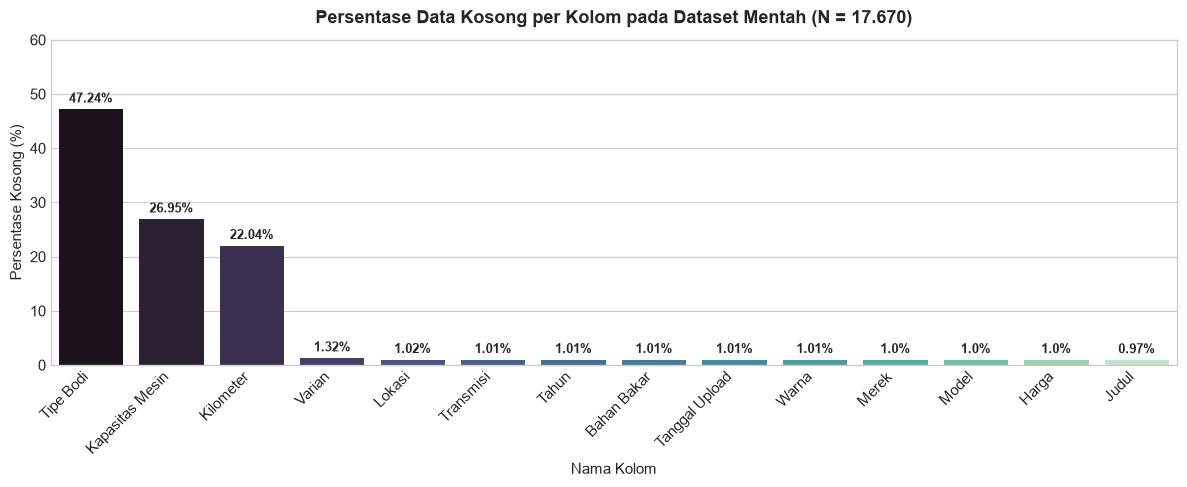

In [5]:
plt.figure(figsize=(12, 5))
missing_plot = missing_summary[missing_summary['Jumlah Kosong'] > 0]
sns.barplot(x=missing_plot.index, y=missing_plot['Persentase (%)'], palette='mako')
plt.title('Persentase Data Kosong per Kolom pada Dataset Mentah (N = 17.670)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Nama Kolom')
plt.ylabel('Persentase Kosong (%)')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 60)
for idx, val in enumerate(missing_plot['Persentase (%)']):
    plt.text(idx, val + 1.2, f"{val}%", ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

### 💡 Interpretasi Kualitas Data, Duplikasi & Ketidakseimbangan Data:
1. **Tipe Bodi (47,24% kosong) & Kapasitas Mesin (26,95% kosong):** Proporsi missing terlalu besar dan tidak seragam antar-platform, sehingga kedua kolom ini didrop di Phase 3.
2. **Kilometer (22,04% kosong / 3.894 baris):** Kosong secara non-acak (selanjutnya dibuktikan hanya terjadi di OLX). Fitur ini tidak didrop karena bernilai prediktif, melainkan dibuatkan indikator `KM_hilang` lalu diimputasi bertingkat **hanya dari median data training pasca-split**.
3. **Harga (1,00% kosong / 176 baris):** Karena `Harga` merupakan variabel target, baris tanpa harga valid tidak boleh diimputasi dan wajib dibuang.
4. **Interpretasi Duplikasi:** Terdapat **1.248 duplikat baris identik penuh (7,06%)** dan **2.089 duplikat URL iklan (11,82%)** pada data mentah. Kemunculan iklan kembar/repost tersebut sangat berbahaya bila tidak dideduplikasi dan dikelompokkan sebelum pembagian data (*train-test split*), karena iklan identik dapat terpecah ke *training* sekaligus *testing* sehingga mengevaluasi akurasi secara semu (*data leakage*).
5. **Catatan *Class Imbalance* (Regresi vs Klasifikasi):** Karena permasalahan proyek ini adalah **regresi** (memprediksi harga kontinu Rupiah), teknik penyeimbangan kelas target seperti SMOTE atau *oversampling* tidak relevan digunakan. Meski demikian, ketimpangan distribusi **kategori merek dan tipe mobil (`Model_Clean`)** tetap dijaga agar seimbang di *train* maupun *test* melalui **`StratifiedGroupKFold`**.

## 5. Pembersihan Ringan Khusus EDA & Penyiapan Pembanding Subset Bersih
Agar analisis statistik dan visualisasi dapat dijalankan akurat tanpa mengotori dataset asli, dibentuk salinan `df_eda` beserta versi terkonsolidasi 5 merek utama dan bebas duplikat (`df_clean_preview`) sebagai pembanding yang transparan.

In [6]:
df_eda = df_raw.copy()

def parse_harga(val):
    if pd.isna(val): return np.nan
    if isinstance(val, (int, float)):
        v = float(val)
    else:
        digits = ''.join(c for c in str(val).replace('.', '').strip() if c.isdigit())
        v = float(digits) if digits else np.nan
    return v if (not pd.isna(v) and v >= 10_000_000) else np.nan

def parse_km(val):
    if pd.isna(val): return np.nan
    s = str(val).lower().replace('km', '').strip()
    is_k = 'k' in s
    s = s.replace('k', '').strip()
    nums = []
    for p in s.split('-'):
        d = ''.join(c for c in p.replace('.', '').replace(',', '').strip() if c.isdigit())
        if d:
            v = float(d)
            if is_k or v <= 500:
                v *= 1000.0
            nums.append(v)
    if not nums: return np.nan
    res = float(np.mean(nums))
    return res if 0 <= res <= 400_000 else np.nan

def parse_tahun(val):
    if pd.isna(val): return np.nan
    digits = ''.join(c for c in str(val) if c.isdigit())
    if digits and len(digits) == 4:
        y = int(digits)
        if 1990 <= y <= 2026: return y
    return np.nan

mercedes_series = [
    'C-Class', 'E-Class', 'GLC-Class', 'GLA-Class', 'CLA-Class', 'GLE-Class',
    'A-Class', 'S-Class', 'GLS-Class', 'V-Class', 'CLS-Class', 'SLK-Class',
    'GLB-Class', 'B-Class', 'ML-Class', 'G-Class', 'GL-Class', 'CLS400',
    'CLA200', 'SL-Class', 'Mercedes Benz'
]
def standardize_brand(m):
    if pd.isna(m): return 'Lainnya'
    ms = str(m).strip()
    if ms in mercedes_series or 'mercedes' in ms.lower() or 'benz' in ms.lower(): return 'Mercedes-Benz'
    for b in ['Toyota', 'Daihatsu', 'Suzuki', 'Honda']:
        if b.lower() in ms.lower(): return b
    return ms

CITY_REGEX = re.compile(r'\b(jakarta|bogor|depok|tangerang|bekasi)\b')
def map_wilayah_eda(loc):
    if pd.isna(loc): return 'Jakarta'
    l = str(loc).lower()
    m = CITY_REGEX.search(l)
    if m: return m.group(1).title()
    if any(k in l for k in ['tangerang','alam sutera','pamulang','banjar wijaya','batu ceper','bsd','cikupa','ciledug','cipondoh','ciputat','citra raya','gading serpong','jatake','jatiuwung','jurangmangu','karawaci','pondok cabe','serpong']): return 'Tangerang'
    if any(k in l for k in ['bekasi','bintara','cibitung','harapan indah','jatiwaringin','jatiwarna','kartini','medan satria','pondok gede']): return 'Bekasi'
    if any(k in l for k in ['depok','cimanggis','kelapa dua']): return 'Depok'
    if any(k in l for k in ['bogor','cibinong','cibubur','cileungsi']): return 'Bogor'
    if any(k in l for k in ['jakarta','ancol','batu tulis','bintaro','buaran','cakung','cempaka putih','cengkareng','cijantung','cilandak','cilincing','cipinang','ciracas','daan mogot','dewi sartika','duren sawit','duri kosambi','fatmawati','grogol','gunung sahari','jalan panjang','kalideres','kebayoran','kebon jeruk','kelapa gading','kemang','kemayoran','kramat jati','kuningan','lebak bulus','lubang buaya','mangga besar','mangga dua','pademangan','pancoran','pantai indah kapuk','pasar minggu','pasar rebo','permata hijau','pluit','pondok indah','pulo gebang','puri indah','sawah besar','setiabudi','sunter','tamansari','taman sari','tambora']): return 'Jakarta'
    return 'Luar Jabodetabek'

df_eda['Harga_Num'] = df_eda['Harga'].apply(parse_harga)
df_eda['KM_Num'] = df_eda['Kilometer'].apply(parse_km)
df_eda['Tahun_Num'] = df_eda['Tahun'].apply(parse_tahun)
df_eda['Usia_Mobil'] = 2025 - df_eda['Tahun_Num']
df_eda['Merek_Clean'] = df_eda['Merek'].apply(standardize_brand)
df_eda['Wilayah'] = df_eda['Lokasi'].apply(map_wilayah_eda)

TARGET_BRANDS = ['Toyota', 'Daihatsu', 'Suzuki', 'Honda', 'Mercedes-Benz']
df_eda_5 = df_eda[
    df_eda['Merek_Clean'].isin(TARGET_BRANDS) &
    df_eda['Harga_Num'].between(25_000_000, 10_000_000_000) &
    df_eda['Tahun_Num'].between(1995, 2025)
].drop_duplicates(subset=['URL']).drop_duplicates(
    subset=['Judul', 'Merek_Clean', 'Tahun_Num', 'Harga_Num', 'Lokasi']
).reset_index(drop=True)

print(f"Mentah terparsing -> Valid Harga (>=10 Jt): {df_eda['Harga_Num'].notna().sum()} | KM: {df_eda['KM_Num'].notna().sum()} | Tahun: {df_eda['Tahun_Num'].notna().sum()}")
print(f"Subset Bersih (5 merek, Rp 25Jt-10M, 1995-2025, bebas URL & repost identik): {len(df_eda_5)} baris")

Mentah terparsing -> Valid Harga (>=10 Jt): 17365 | KM: 13767 | Tahun: 17471
Subset Bersih (5 merek, Rp 25Jt-10M, 1995-2025, bebas URL & repost identik): 13359 baris


## 6. Statistik Deskriptif Variabel Numerik (Mentah vs Subset Bersih)
Untuk keterbukaan penuh antara kondisi dataset mentah (*pre-filtering*) dan cakupan data yang masuk ke pemodelan (*5 merek utama, bebas duplikat, Rp 25 Juta–10 Miliar, 1995–2025*), tabel statistik disajikan untuk **keduanya**.

In [7]:
cols_num = ['Harga_Num', 'KM_Num', 'Tahun_Num', 'Usia_Mobil']
desc_raw = df_eda[cols_num].describe().T
desc_raw['median'] = df_eda[cols_num].median()
desc_raw['IQR'] = desc_raw['75%'] - desc_raw['25%']

desc_clean = df_eda_5[cols_num].describe().T
desc_clean['median'] = df_eda_5[cols_num].median()
desc_clean['IQR'] = desc_clean['75%'] - desc_clean['25%']

print("=== A. STATISTIK DESKRIPTIF DATA MENTAH TERPARSING (PRA-FILTERING) ===")
print(desc_raw[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'max', 'IQR']].to_string())
print("\n=== B. STATISTIK DESKRIPTIF SUBSET BERSIH 5 MEREK BEBAS DUPLIKAT ===")
print(desc_clean[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'max', 'IQR']].to_string())

=== A. STATISTIK DESKRIPTIF DATA MENTAH TERPARSING (PRA-FILTERING) ===
              count          mean       median           std         min          25%          75%           max          IQR
Harga_Num   17365.0  2.817275e+08  182000000.0  3.648165e+08  20000000.0  130000000.0  300000000.0  7.999000e+09  170000000.0
KM_Num      13767.0  6.144708e+04      52500.0  4.063494e+04      1000.0      32500.0      87500.0  3.125000e+05      55000.0
Tahun_Num   17471.0  2.018869e+03       2019.0  4.104320e+00      1990.0       2017.0       2022.0  2.025000e+03          5.0
Usia_Mobil  17471.0  6.130616e+00          6.0  4.104320e+00         0.0          3.0          8.0  3.500000e+01          5.0

=== B. STATISTIK DESKRIPTIF SUBSET BERSIH 5 MEREK BEBAS DUPLIKAT ===
              count          mean       median           std         min          25%          75%           max          IQR
Harga_Num   13359.0  2.877875e+08  185000000.0  3.885629e+08  27000000.0  131000000.0  310000000.0  7.9

### 💡 Interpretasi Statistik Deskriptif:
- **Pada Data Mentah Terparsing (*Pra-Filtering*, $N = 17.365$ harga $\ge$ Rp 10 jt):**
  - **Harga:** Mean **Rp 281,7 Juta**, median **Rp 182 Juta** (Q1 **Rp 130 Juta**, Q3 **Rp 300 Juta**, IQR **Rp 170 Juta**), mencerminkan dominasi mobil massal yang tertarik ke kanan oleh unit mewah miliaran.
  - **Tahun & Usia:** Valid pada **17.471** baris (rentang 1990–2025), kuartil **2017–2022** dengan median tahun **2019** (usia median **6 tahun**; mean tahun **2018,9**).
  - **Kilometer:** Valid pada **13.767** baris, median **52.500 KM** (mean **61.447 KM**, IQR **55.000 KM**).
- **Pada Subset Bersih 5 Merek Bebas Duplikat ($N = 13.359$ sebelum penyaringan anomali A6):**
  - Mean harga berada pada **Rp 287,8 Juta** dan median **Rp 185 Juta** (Q1 **Rp 131 Juta**, Q3 **Rp 310 Juta**, IQR **Rp 179 Juta**), median tahun **2019** (usia **6 tahun**), dan median kilometer **52.500 KM** (mean **58.818 KM** pada 10.426 baris ber-KM).

## 7. Analisis Distribusi Target Harga & Fitur Numerik (`KM`, `Tahun`, `Usia`)
Membandingkan distribusi nominal harga vs transformasi $\\log(1 + \\text{Harga})$, serta memvisualisasikan histogram ketiga fitur numerik utama (`KM_Num`, `Tahun_Num`, `Usia_Mobil`).

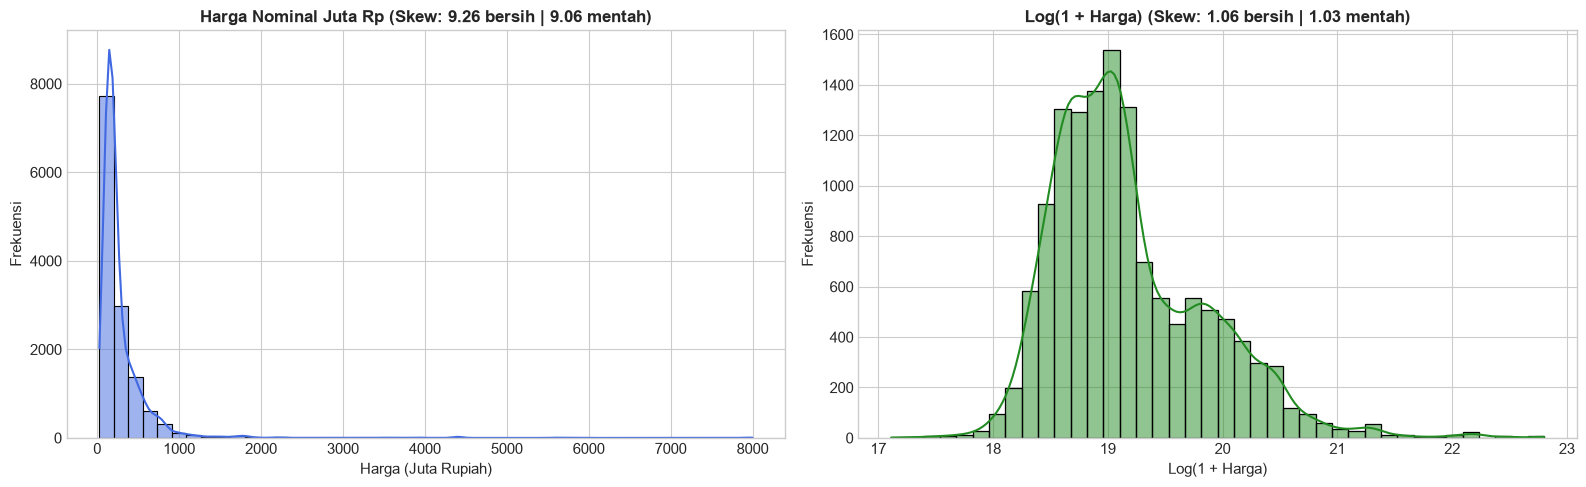

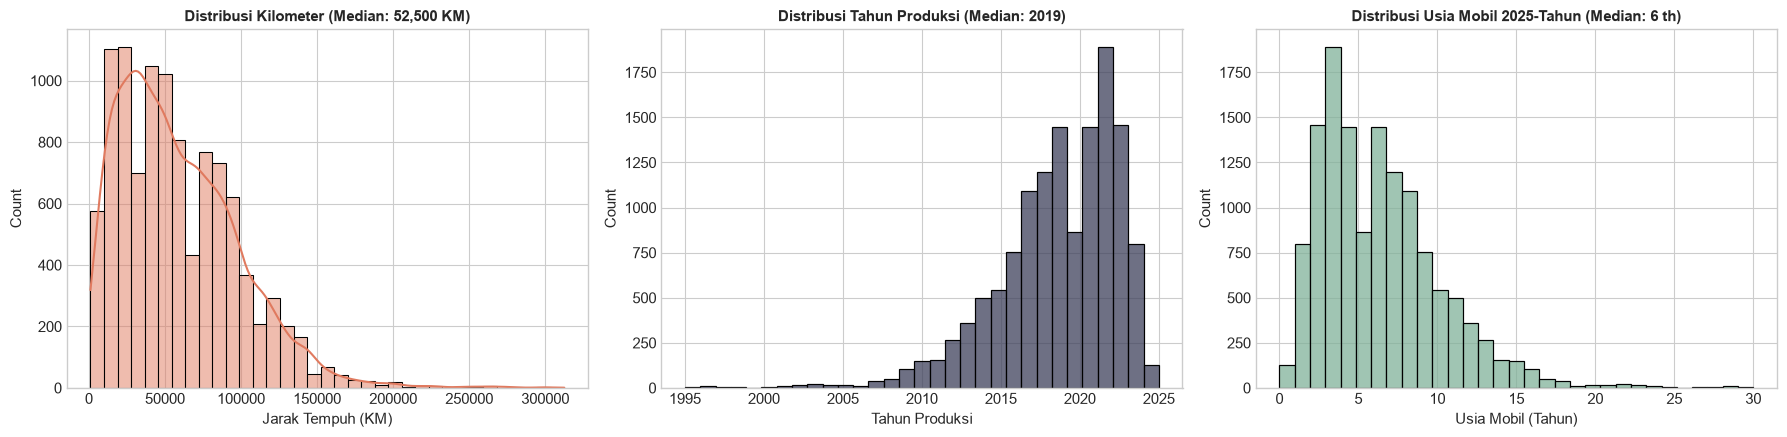

Skewness Harga -> Mentah: 9.06 | Bersih: 9.26
Skewness Log(1+Harga) -> Mentah: 1.03 | Bersih: 1.06


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
raw_skew = df_eda['Harga_Num'].skew()
clean_skew = df_eda_5['Harga_Num'].skew()
sns.histplot(df_eda_5['Harga_Num'].dropna() / 1e6, kde=True, ax=axes[0], color='royalblue', bins=45)
axes[0].set_title(f"Harga Nominal Juta Rp (Skew: {clean_skew:.2f} bersih | {raw_skew:.2f} mentah)", fontsize=12, fontweight='bold')
axes[0].set_xlabel('Harga (Juta Rupiah)')
axes[0].set_ylabel('Frekuensi')

log_h_clean = np.log1p(df_eda_5['Harga_Num'].dropna())
log_h_raw = np.log1p(df_eda['Harga_Num'].dropna())
sns.histplot(log_h_clean, kde=True, ax=axes[1], color='forestgreen', bins=40)
axes[1].set_title(f"Log(1 + Harga) (Skew: {log_h_clean.skew():.2f} bersih | {log_h_raw.skew():.2f} mentah)", fontsize=12, fontweight='bold')
axes[1].set_xlabel('Log(1 + Harga)')
axes[1].set_ylabel('Frekuensi')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(df_eda_5['KM_Num'].dropna(), kde=True, ax=axes[0], color='#e07a5f', bins=35)
axes[0].set_title(f"Distribusi Kilometer (Median: {df_eda_5['KM_Num'].median():,.0f} KM)", fontsize=11, fontweight='bold')
axes[0].set_xlabel('Jarak Tempuh (KM)')

sns.histplot(df_eda_5['Tahun_Num'].dropna(), ax=axes[1], color='#3d405b', bins=31)
axes[1].set_title(f"Distribusi Tahun Produksi (Median: {int(df_eda_5['Tahun_Num'].median())})", fontsize=11, fontweight='bold')
axes[1].set_xlabel('Tahun Produksi')

sns.histplot(df_eda_5['Usia_Mobil'].dropna(), ax=axes[2], color='#81b29a', bins=31)
axes[2].set_title(f"Distribusi Usia Mobil 2025-Tahun (Median: {int(df_eda_5['Usia_Mobil'].median())} th)", fontsize=11, fontweight='bold')
axes[2].set_xlabel('Usia Mobil (Tahun)')
plt.tight_layout()
plt.show()

print(f"Skewness Harga -> Mentah: {raw_skew:.2f} | Bersih: {clean_skew:.2f}")
print(f"Skewness Log(1+Harga) -> Mentah: {log_h_raw.skew():.2f} | Bersih: {log_h_clean.skew():.2f}")

### 💡 Temuan Kritis Distribusi Target & Fitur Numerik:
1. **Kemencengan Target & Transformasi Logaritma:** Pada data mentah, distribusi `Harga` sangat menceng ke kanan (*skewness* **9,06**; pada subset bersih **9,26**). Transformasi $\log(1 + \text{Harga})$ menurunkan *skewness* secara drastis menjadi **1,03** (data mentah) / **1,06** (subset bersih). Meskipun turun tajam, histogram $\log(1 + \text{Harga})$ terlihat **masih condong ke kanan secara moderat (*moderately right-skewed*)**, bukannya simetris sempurna, akibat kelompok populasi mobil mewah Mercedes-Benz dan MPV premium di sisi kanan distribusi.
2. **Distribusi Fitur Numerik:** Histogram `KM_Num` menceng ke kanan (terkonsentrasi pada rentang 20.000–90.000 KM), sedangkan `Tahun_Num` terkonsentrasi pada mobil usia muda (**2017–2023**) dan mencerminkan cermin sempurna terhadap `Usia_Mobil` ($r = -1{,}000$, sehingga cukup satu fitur saja dipakai di pemodelan agar bebas multikolinearitas sempurna).
3. **Strategi Target:** Model regresi tetap dilatih menggunakan $\log(1 + \text{Harga})$ untuk menstabilkan variansi residual dari skala ratusan juta ke log-skala, lalu dikembalikan ke Rupiah via $\exp(\hat{y}) - 1$ pada aplikasi web FastAPI maupun arsip Streamlit.

## 8. Analisis Sebaran Fitur Kategorikal (Setelah Konsolidasi Merek & Pemetaan Wilayah)
Menganalisis distribusi 5 merek utama setelah penyatuan seri Mercedes-Benz, proporsi transmisi, jenis bahan bakar, dan cakupan wilayah Jabodetabek hasil pemetaan.

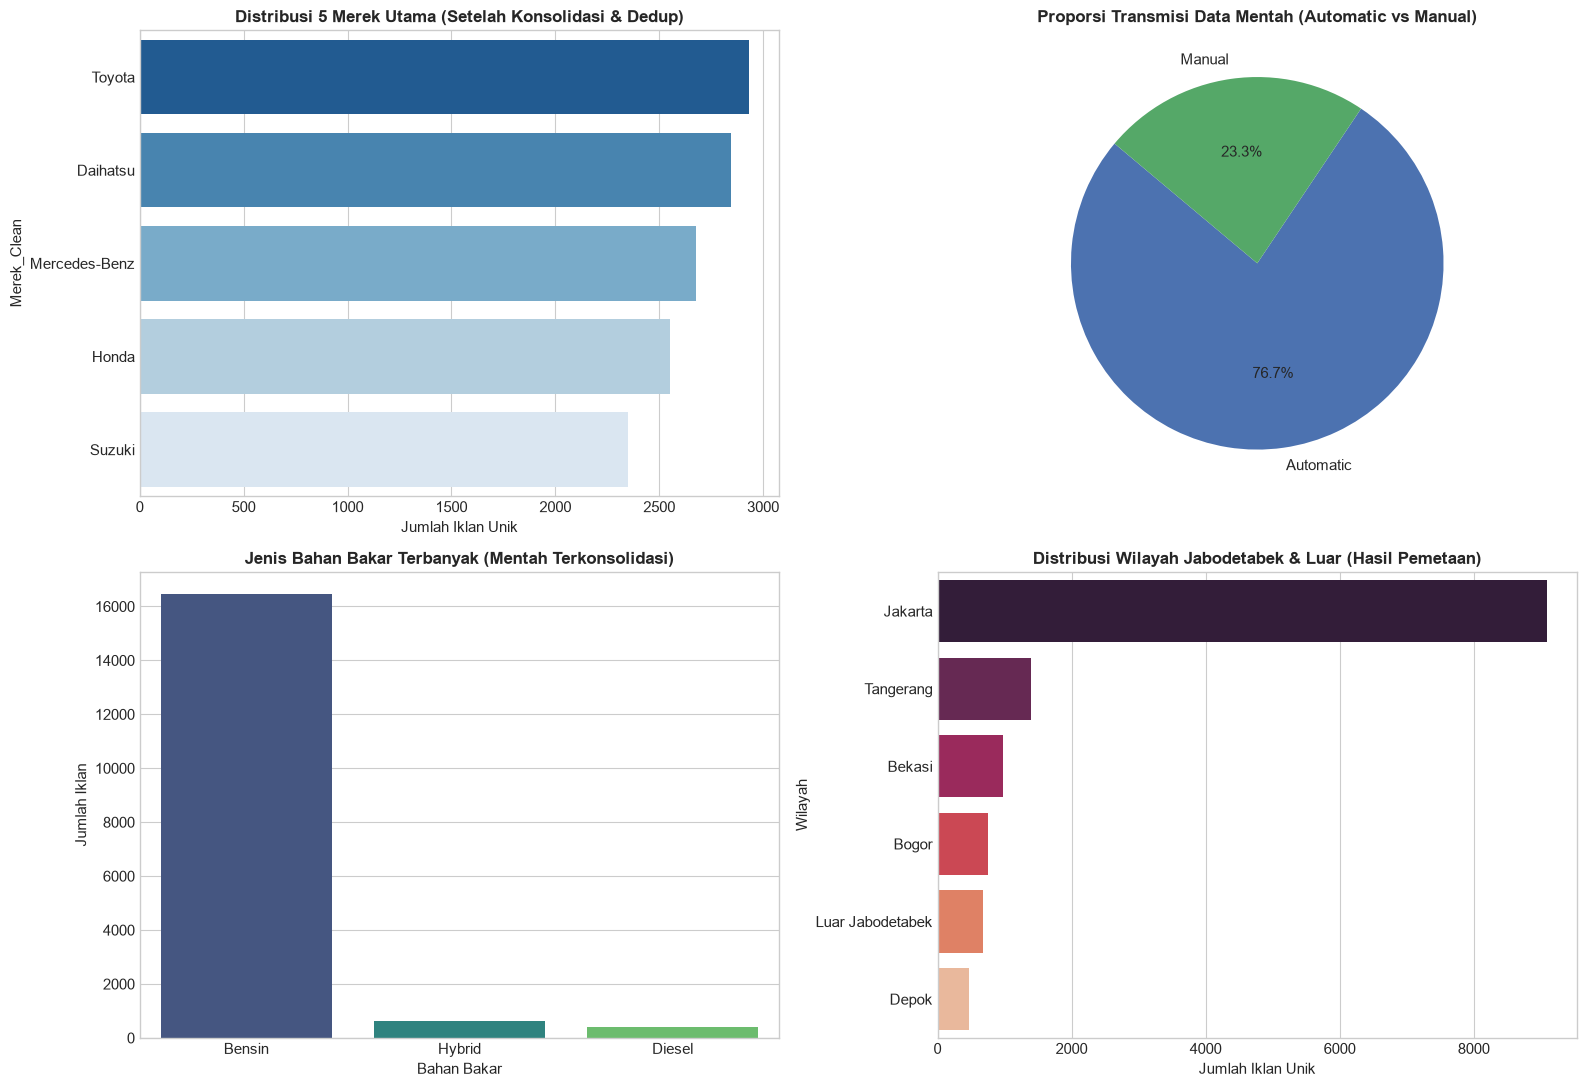

5 Merek Utama (mentah terkonsolidasi pra-dedup): {'Toyota': 3785, 'Daihatsu': 3451, 'Mercedes-Benz': 3354, 'Suzuki': 3246, 'Honda': 3121}
5 Merek Utama (subset bersih bebas dedup): {'Toyota': 2931, 'Daihatsu': 2845, 'Mercedes-Benz': 2677, 'Honda': 2554, 'Suzuki': 2352}
Transmisi mentah (%): {'Automatic': 13411, 'Manual': 4073} | {'Automatic': 76.7, 'Manual': 23.3}
Bahan Bakar mentah di subset bersih (termasuk 1 Listrik): {'Bensin': 7085, 'Petrol': 5386, 'Hybrid': 541, 'Diesel': 346, 'Listrik': 1}
Wilayah Jabodetabek (subset bersih): {'Jakarta': 9085, 'Tangerang': 1393, 'Bekasi': 975, 'Bogor': 753, 'Luar Jabodetabek': 682, 'Depok': 471}


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

brand_counts = df_eda_5['Merek_Clean'].value_counts()
sns.barplot(x=brand_counts.values, y=brand_counts.index, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Distribusi 5 Merek Utama (Setelah Konsolidasi & Dedup)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Jumlah Iklan Unik')

trans_raw = df_eda['Transmisi'].value_counts().head(2)
axes[0, 1].pie(trans_raw.values, labels=trans_raw.index, autopct='%1.1f%%', colors=['#4C72B0', '#55A868'], startangle=140)
axes[0, 1].set_title('Proporsi Transmisi Data Mentah (Automatic vs Manual)', fontsize=12, fontweight='bold')

fuel_norm = df_eda['Bahan Bakar'].replace({'Petrol': 'Bensin', 'Bensin - Hybrid': 'Hybrid', 'Listrik': 'Hybrid/Listrik'}).value_counts()
fuel_top = fuel_norm.head(3)
sns.barplot(x=fuel_top.index, y=fuel_top.values, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Jenis Bahan Bakar Terbanyak (Mentah Terkonsolidasi)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Jumlah Iklan')

wil_counts = df_eda_5['Wilayah'].value_counts()
sns.barplot(x=wil_counts.values, y=wil_counts.index, ax=axes[1, 1], palette='rocket')
axes[1, 1].set_title('Distribusi Wilayah Jabodetabek & Luar (Hasil Pemetaan)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Jumlah Iklan Unik')

plt.tight_layout()
plt.show()

print("5 Merek Utama (mentah terkonsolidasi pra-dedup):", df_eda[df_eda['Merek_Clean'].isin(TARGET_BRANDS)]['Merek_Clean'].value_counts().to_dict())
print("5 Merek Utama (subset bersih bebas dedup):", brand_counts.to_dict())
trans_pct = (trans_raw / trans_raw.sum() * 100).round(1)
print("Transmisi mentah (%):", trans_raw.to_dict(), "|", trans_pct.to_dict())
fuel_clean_vc = df_eda_5['Bahan Bakar'].value_counts().to_dict()
print("Bahan Bakar mentah di subset bersih (termasuk 1 Listrik):", fuel_clean_vc)
print("Wilayah Jabodetabek (subset bersih):", wil_counts.to_dict())

### 💡 Interpretasi Fitur Kategorikal:
- **Keseimbangan 5 Merek Utama:** Berbeda dari kolom `Merek` mentah di mana Mercedes-Benz hanya terbaca `2.157` iklan karena serinya terpecah (`C-Class`, `E-Class`, `GLC-Class`, dll.), setelah konsolidasi seluruh seri merek (`3.354` baris pra-dedup), pada subset bersih jumlah iklan antar 5 merek relatif seimbang: **Toyota (2.931)**, **Daihatsu (2.845)**, **Mercedes-Benz (2.677)**, **Honda (2.554)**, dan **Suzuki (2.352)**.
- **Transmisi & Bahan Bakar:** Transmisi *Automatic* mendominasi pasar dengan proporsi **76,7%** (`13.411` vs `4.073` Manual pada data mentah). Pada subset bersih, bahan bakar didominasi **Bensin/Petrol (`7.085 + 5.386 = 12.471` iklan atau 93,4%)**, disusul **Hybrid (`541` + `1 Listrik` atau 4,1%)**, dan **Diesel (`346` iklan atau 2,6%)**.
- **Wilayah:** Setelah perbaikan aturan nama kota eksplisit + label diskon `'% off'` Mobil123, **94,9%** iklan terkonsentrasi di **Jabodetabek** (**Jakarta 9.085**, **Tangerang 1.393**, **Bekasi 975**, **Bogor 753**, **Depok 471**) berbanding **682** unit **Luar Jabodetabek**.

## 9. Analisis Antar-Platform (`OLX` vs `Mobil123`) — Dasar Keputusan Preprocessing
Memeriksa secara kuantitatif tiga perbedaan sistematis antara sumber scraping **OLX** dan **Mobil123** sebagai landasan ilmiah rekayasa fitur di Phase 3:
1. Pola kekosongan fitur Kilometer (`KM_Num`) per platform dan kaitannya dengan level harga (dasar fitur **`KM_hilang`**).
2. Fragmentasi dan ketidakkonsistenan penamaan tipe kendaraan (`Model`) per platform (dasar **kamus normalisasi & keluarga model Mercedes + `Varian`**).
3. Sebaran harga median antar-platform per merek untuk menguji indikasi bias platform.

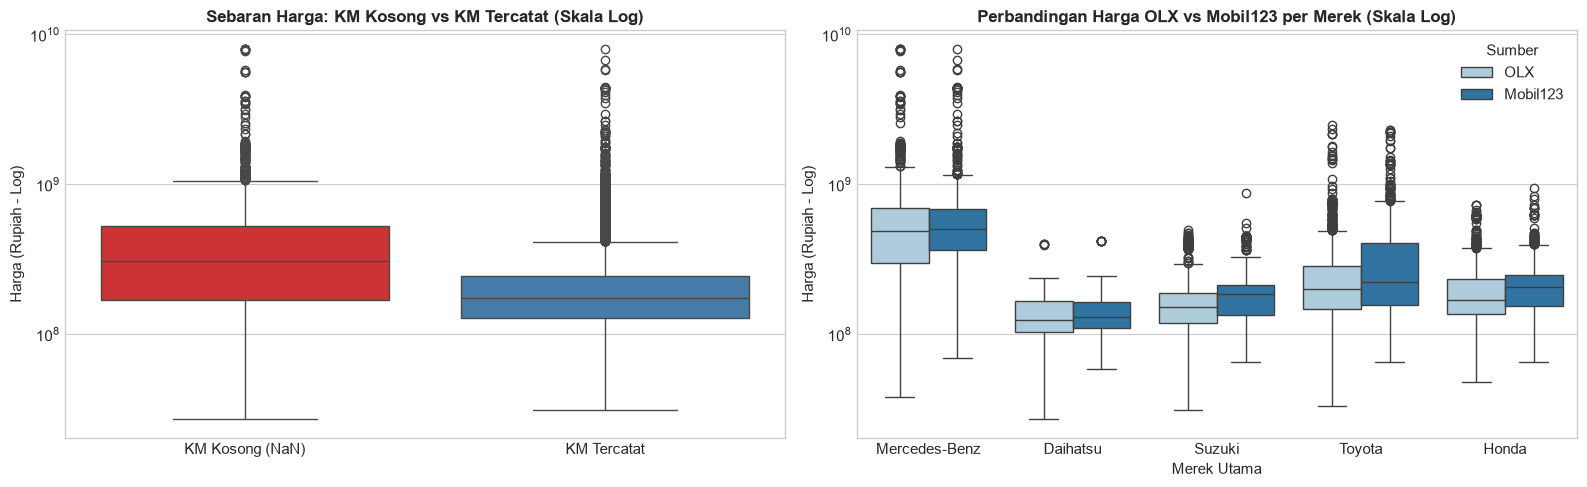

Proporsi KM kosong per Sumber (%): {'Mobil123': 0.02, 'OLX': 39.68}
Median Harga berdasarkan Status KM (Rupiah): {'KM Kosong (NaN)': 310000000.0, 'KM Tercatat': 174000000.0}

Median Harga OLX vs Mobil123 per Merek (Juta Rupiah):
Sumber         Mobil123    OLX
Merek_Clean                   
Daihatsu          129.5  124.0
Honda             205.0  170.0
Mercedes-Benz     500.0  489.0
Suzuki            185.0  152.0
Toyota            223.0  199.0

Total kombinasi Merek+Model mentah: 222 | Muncul di 1 platform saja: 114 (51.4%)
Model unik Mercedes-Benz -> OLX: 113 vs Mobil123: 62


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Missing KM by Sumber & Median Price Comparison
km_miss_rate = df_eda_5.groupby('Sumber')['KM_Num'].apply(lambda s: s.isna().mean() * 100)
km_flag_price = df_eda_5.assign(Status_KM=np.where(df_eda_5['KM_Num'].isna(), 'KM Kosong (NaN)', 'KM Tercatat'))
sns.boxplot(x='Status_KM', y='Harga_Num', data=km_flag_price, ax=axes[0], palette='Set1')
axes[0].set_yscale('log')
axes[0].set_title('Sebaran Harga: KM Kosong vs KM Tercatat (Skala Log)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Harga (Rupiah - Log)')

# 2. Harga per Platform per Merek
sns.boxplot(x='Merek_Clean', y='Harga_Num', hue='Sumber', data=df_eda_5, ax=axes[1], palette='Paired')
axes[1].set_yscale('log')
axes[1].set_title('Perbandingan Harga OLX vs Mobil123 per Merek (Skala Log)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Merek Utama')
axes[1].set_ylabel('Harga (Rupiah - Log)')
plt.tight_layout()
plt.show()

print("Proporsi KM kosong per Sumber (%):", km_miss_rate.round(2).to_dict())
print("Median Harga berdasarkan Status KM (Rupiah):", km_flag_price.groupby('Status_KM')['Harga_Num'].median().to_dict())
print("\nMedian Harga OLX vs Mobil123 per Merek (Juta Rupiah):")
med_plat = (df_eda_5.groupby(['Merek_Clean', 'Sumber'])['Harga_Num'].median().unstack() / 1e6).round(1)
print(med_plat)

# 3. Model fragmentation stats
df_m_clean_tmp = df_eda_5['Model'].fillna('Lainnya').astype(str).str.strip().str.title()
mm_tmp = df_eda_5['Merek_Clean'] + "_" + df_m_clean_tmp
src_cnt = df_eda_5.assign(MM=mm_tmp).groupby('MM')['Sumber'].nunique()
mb_olx = df_eda_5[(df_eda_5['Merek_Clean']=='Mercedes-Benz') & (df_eda_5['Sumber']=='OLX')]['Model'].nunique()
mb_m123 = df_eda_5[(df_eda_5['Merek_Clean']=='Mercedes-Benz') & (df_eda_5['Sumber']=='Mobil123')]['Model'].nunique()
print(f"\nTotal kombinasi Merek+Model mentah: {len(src_cnt)} | Muncul di 1 platform saja: {(src_cnt==1).sum()} ({(src_cnt==1).mean()*100:.1f}%)")
print(f"Model unik Mercedes-Benz -> OLX: {mb_olx} vs Mobil123: {mb_m123}")

### 💡 Temuan Empiris Antar-Platform:
1. **Sinyal Kuat pada `KM_Num` Hilang (`KM_hilang`):** Kekosongan data odometer terjadi terutama pada **OLX sebesar 39,68%** dibanding hanya **0,02% di Mobil123**. Terlebih lagi, median harga unit ber-KM kosong jauh lebih tinggi (**Rp 310 Juta**) dibanding yang ber-KM tercatat (**Rp 174 Juta**). Mengisi nilai kosong hanya dengan median tanpa menambahkan indikator `KM_hilang (0/1)` akan menghapus sinyal informasi tersebut.
2. **Fragmentasi Nama Model Lintas Platform:** Dari **222** kombinasi `Merek + Model` mentah, **114 (51,4%)** hanya muncul di satu platform. Contoh nyatanya adalah **Honda `Brio Satya` (`229` baris hanya di OLX)** yang terpisah dari `Brio`, **Toyota `Corolla` / `Altis` / `Corolla Altis`**, **Suzuki `Vitara` / `Grand Vitara`**, variasi spasi (`Cls350` vs `Cls 350`, `Ml350` vs `Ml 350`), dan pemisahan ekstrim pada **Mercedes-Benz** (`113` kode unik seperti `E260`/`G63`/`S450` di OLX vs `62` label seperti `E-Class`/`G-Class` di Mobil123). Oleh karena itu, Phase 3 wajib menerapkan **kamus normalisasi model & keluarga model Mercedes + ekstraksi `Varian_Clean`**.
3. **Perbedaan Segmen Harga OLX vs Mobil123:** Di seluruh merek utama, median harga **Mobil123** konsisten lebih tinggi daripada OLX — misalnya **Honda Rp 205,0 Jt vs Rp 170,0 Jt**, **Suzuki Rp 185,0 Jt vs Rp 152,0 Jt**, **Toyota Rp 223,0 Jt vs Rp 199,0 Jt**, **Daihatsu Rp 129,5 Jt vs Rp 124,0 Jt**, dan **Mercedes-Benz Rp 500,0 Jt vs Rp 489,0 Jt** (mencerminkan dominasi unit dealer bergaransi di Mobil123).

## 10. Analisis Outlier per Merek (Boxplot & Metode IQR)
Memeriksa sebaran harga dan batas outlier metode *Interquartile Range* (IQR) baik secara global maupun **di dalam masing-masing 5 merek terkonsolidasi** (mengingat segmen harga Mercedes-Benz jauh di atas merek massal).

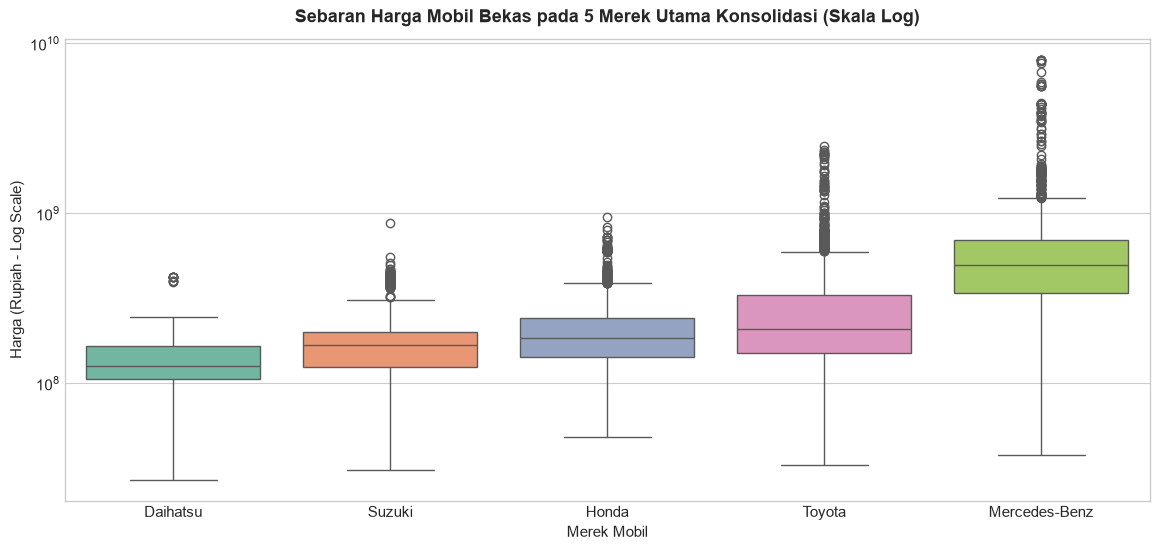

=== OUTLIER HARGA METODE IQR PER MEREK (SUBSET BERSIH) ===
        Merek    N  Median (Jt)  Batas Atas IQR (Jt)  Jumlah Outlier  Persen (%)
     Daihatsu 2845        126.0                253.5              11        0.39
       Suzuki 2352        167.0                312.5             134        5.70
        Honda 2554        185.0                388.9             131        5.13
       Toyota 2931        210.0                597.5             196        6.69
Mercedes-Benz 2677        495.0               1232.5             165        6.16

Pembanding Global Mentah -> Batas Atas: Rp 555,000,000 | Outlier: 1697 (9.77%)


In [11]:
plt.figure(figsize=(14, 6))
order_brands = df_eda_5.groupby('Merek_Clean')['Harga_Num'].median().sort_values().index
sns.boxplot(x='Merek_Clean', y='Harga_Num', data=df_eda_5, order=order_brands, palette='Set2')
plt.title('Sebaran Harga Mobil Bekas pada 5 Merek Utama Konsolidasi (Skala Log)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Merek Mobil')
plt.ylabel('Harga (Rupiah - Log Scale)')
plt.yscale('log')
plt.show()

rows_iqr = []
for b in order_brands:
    s = df_eda_5[df_eda_5['Merek_Clean'] == b]['Harga_Num']
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lb, ub = max(0, q1 - 1.5 * iqr), q3 + 1.5 * iqr
    out_n = int(((s < q1 - 1.5 * iqr) | (s > ub)).sum())
    rows_iqr.append({
        'Merek': b, 'N': len(s), 'Median (Jt)': round(s.median()/1e6, 1),
        'Batas Atas IQR (Jt)': round(ub/1e6, 1), 'Jumlah Outlier': out_n, 'Persen (%)': round(out_n/len(s)*100, 2)
    })
print("=== OUTLIER HARGA METODE IQR PER MEREK (SUBSET BERSIH) ===")
print(pd.DataFrame(rows_iqr).to_string(index=False))

q1_g, q3_g = df_eda['Harga_Num'].quantile(0.25), df_eda['Harga_Num'].quantile(0.75)
iqr_g = q3_g - q1_g
out_g = df_eda[(df_eda['Harga_Num'] < q1_g - 1.5*iqr_g) | (df_eda['Harga_Num'] > q3_g + 1.5*iqr_g)]
print(f"\nPembanding Global Mentah -> Batas Atas: Rp {q3_g + 1.5*iqr_g:,.0f} | Outlier: {len(out_g)} ({len(out_g)/df_eda['Harga_Num'].notna().sum()*100:.2f}%)")

### 💡 Interpretasi Outlier & Penanganan Anomali Data:
- **Outlier Natural vs Salah Input:** Pada evaluasi IQR **per merek** (subset bersih), proporsi outlier masing-masing merek berkisar **0,39% hingga 6,69%** (*Daihatsu 0,39% / 11 unit, Honda 5,13% / 131 unit, Suzuki 5,70% / 134 unit, Mercedes-Benz 6,16% / 165 unit, Toyota 6,69% / 196 unit*), yang merupakan varian premium asli seperti Alphard/Land Cruiser pada Toyota atau Maybach/G-Class pada Mercedes-Benz, bukan anomali gabungan seperti IQR global (**9,77%**).
- **Keputusan:** Outlier harga natural dari varian tinggi tetap dipertahankan (dibantu transformasi $\log(1+\text{Harga})$ dan fitur `Model_Clean` + `Varian_Clean`), sedangkan **hanya baris yang terbukti salah ketik/salah label** (seperti *Karimun Wagon R 2020 Rp 880 jt*, *Yaris 2019 Rp 1,99 M*, *Camry 2002 tertulis tahun 2020*, iklan *Smart/Lexus* atau silang-merek, serta *unit $\ge 2023$ dengan KM $> 80.000$*) yang diinspeksi dan disaring di Phase 3.

## 11. Analisis Korelasi Pearson & Visualisasi Hubungan Numerik
Mengkaji korelasi Pearson fitur numerik terhadap `Harga_Num` maupun `Log_Harga`, dilengkapi scatter plot menggunakan 5 merek terkonsolidasi (`Merek_Clean`).

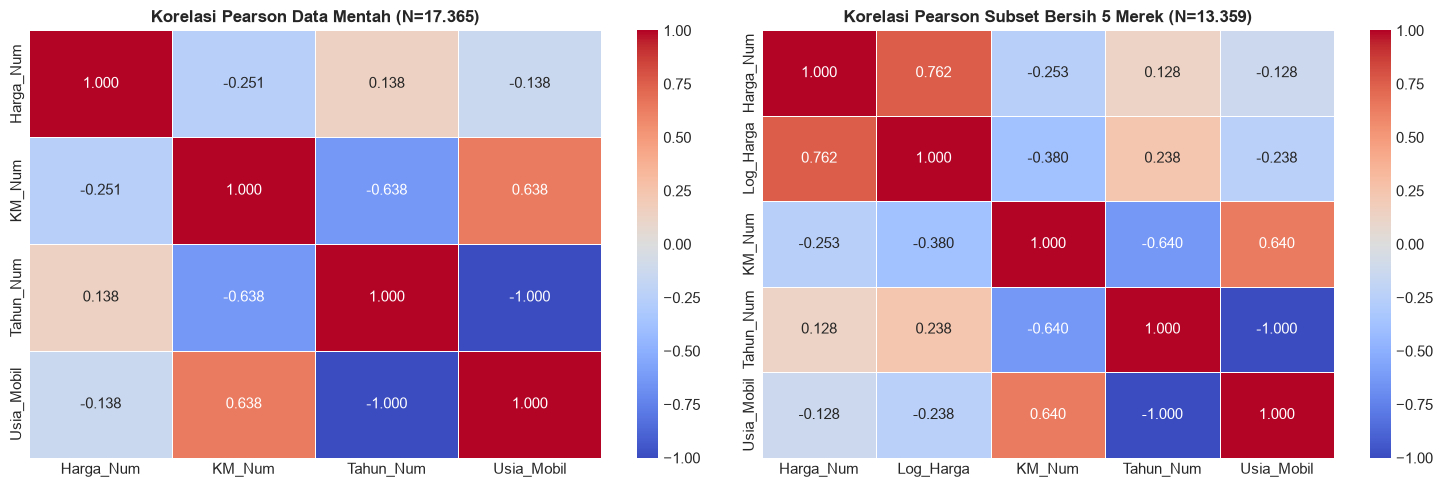

Korelasi terhadap Harga_Num (Mentah): {'Harga_Num': 1.0, 'KM_Num': -0.251, 'Tahun_Num': 0.138, 'Usia_Mobil': -0.138}
Korelasi terhadap Harga_Num (Bersih): {'Harga_Num': 1.0, 'Log_Harga': 0.762, 'KM_Num': -0.253, 'Tahun_Num': 0.128, 'Usia_Mobil': -0.128}
Korelasi terhadap Log_Harga (Bersih): {'Harga_Num': 0.762, 'Log_Harga': 1.0, 'KM_Num': -0.38, 'Tahun_Num': 0.238, 'Usia_Mobil': -0.238}


In [12]:
corr_raw = df_eda[['Harga_Num', 'KM_Num', 'Tahun_Num', 'Usia_Mobil']].corr()
df_eda_5_log = df_eda_5.assign(Log_Harga=np.log1p(df_eda_5['Harga_Num']))
corr_clean = df_eda_5_log[['Harga_Num', 'Log_Harga', 'KM_Num', 'Tahun_Num', 'Usia_Mobil']].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(corr_raw, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Korelasi Pearson Data Mentah (N=17.365)', fontsize=12, fontweight='bold')
sns.heatmap(corr_clean, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Korelasi Pearson Subset Bersih 5 Merek (N=13.359)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("Korelasi terhadap Harga_Num (Mentah):", corr_raw['Harga_Num'].round(3).to_dict())
print("Korelasi terhadap Harga_Num (Bersih):", corr_clean['Harga_Num'].round(3).to_dict())
print("Korelasi terhadap Log_Harga (Bersih):", corr_clean['Log_Harga'].round(3).to_dict())

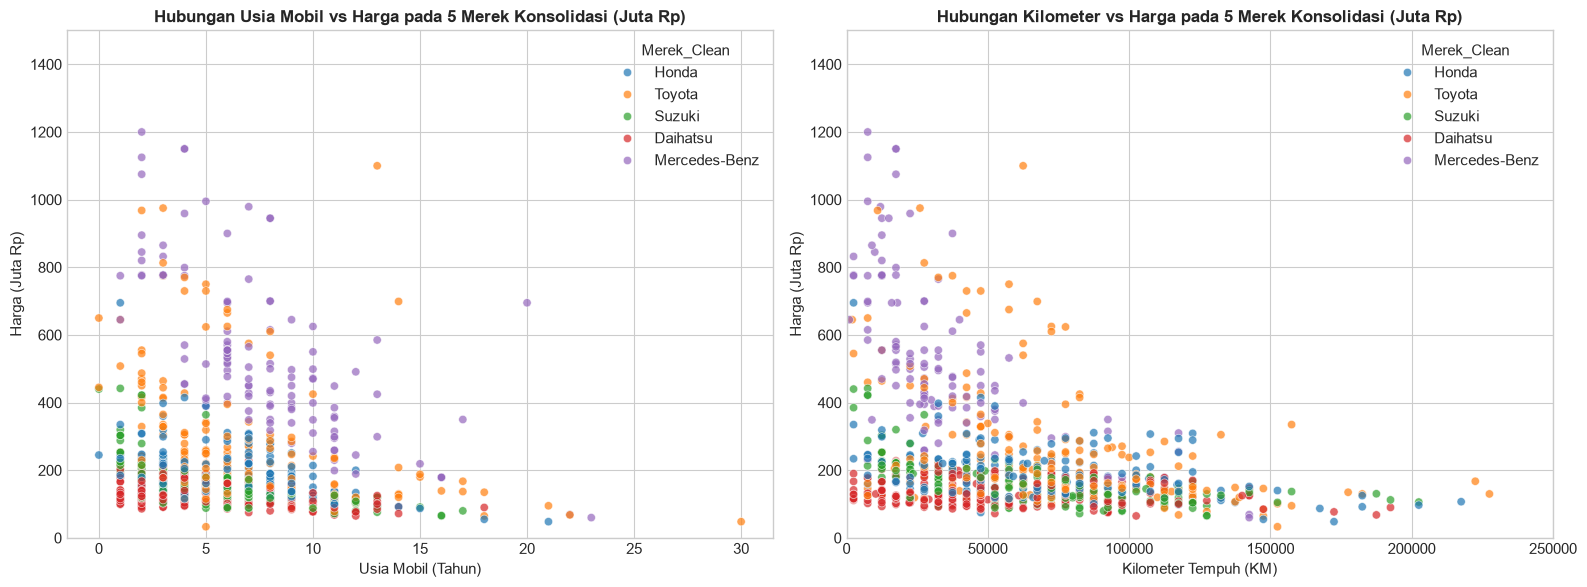

In [13]:
sample_eda = df_eda_5.dropna(subset=['Usia_Mobil', 'Harga_Num', 'KM_Num']).sample(n=1000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x='Usia_Mobil', y=sample_eda['Harga_Num']/1e6, hue='Merek_Clean', data=sample_eda, ax=axes[0], alpha=0.7)
axes[0].set_title('Hubungan Usia Mobil vs Harga pada 5 Merek Konsolidasi (Juta Rp)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Usia Mobil (Tahun)')
axes[0].set_ylabel('Harga (Juta Rp)')
axes[0].set_ylim(0, 1500)

sns.scatterplot(x='KM_Num', y=sample_eda['Harga_Num']/1e6, hue='Merek_Clean', data=sample_eda, ax=axes[1], alpha=0.7)
axes[1].set_title('Hubungan Kilometer vs Harga pada 5 Merek Konsolidasi (Juta Rp)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kilometer Tempuh (KM)')
axes[1].set_ylabel('Harga (Juta Rp)')
axes[1].set_xlim(0, 250000)
axes[1].set_ylim(0, 1500)
plt.tight_layout()
plt.show()

### 💡 Interpretasi Hubungan Antar-Variabel:
1. **Tahun Produksi / Usia vs Harga Nominal:** Pada data mentah korelasi Pearson `Tahun_Num` terhadap `Harga_Num` bernilai **$r = +0{,}138$** (`Usia_Mobil` $r = -0{,}138$; pada subset bersih $+0{,}128$ / $-0{,}128$), yang merupakan **korelasi linier positif lemah** ($< 0{,}20$). Hubungan tersebut menguat pada skala `Log_Harga` ($r = +0{,}238$ untuk `Tahun_Num` dan $r = -0{,}238$ untuk `Usia_Mobil`) karena efek ekstrem unit mewah miliaran terkompresi oleh logaritma.
2. **Jarak Tempuh (Kilometer) vs Harga Nominal:** Korelasi `KM_Num` terhadap `Harga_Num` bernilai **$r = -0{,}251$** (data mentah) / **$-0{,}253$** (bersih) dan meningkat menjadi **$-0{,}380$** pada skala `Log_Harga`, mengonfirmasi tren depresiasi harga seiring bertambahnya pemakaian kendaraan.
3. **Kolinearitas Sempurna `Tahun_Num` & `Usia_Mobil`:** Terbaca jelas $r = -1{,}000$ karena `Usia_Mobil = 2025 - Tahun_Num`. Pada Phase 3 cukup mempertahankan satu fitur saja (**`Usia_Mobil`**) untuk mencegah multikolinearitas sempurna.
4. **Merek & Tipe sebagai Moderator:** Scatter plot memperlihatkan pemisahan strata harga yang sangat tegas antara **Mercedes-Benz** dan keempat merek Jepang pada usia serta kilometer yang identik.

## 12. Kesimpulan EDA & Rekomendasi Konkret Preprocessing (Phase 3)

| No. | Aspek Temuan EDA | Rencana Tindakan Konkret di Phase 3 |
|---|---|---|
| **1** | **Target Missing, Skala Skew & Anomali Input** | Hapus 176 baris missing `Harga` + outlier tak rasional (< Rp 25 Jt / > Rp 10 M), gunakan transformasi $\log(1 + \text{Harga})$, serta buang baris salah input terinspeksi (salah ketik digit harga, selisih tahun judul $\ge 5$ th, merek silang/Smart/Lexus, dan unit $\ge 2023$ dengan KM $> 80.000$). |
| **2** | **Fragmentasi Model Antar Platform (114/222)** | Normalisasi kamus tipe (`Brio Satya` $\rightarrow$ `Brio`, `Corolla`/`Altis` $\rightarrow$ `Corolla Altis`, `Vitara` $\rightarrow$ `Grand Vitara`, spasi), turunkan keluarga model Mercedes (`C-Class`, `E-Class`, dst.), dan ekstrak `Varian_Clean`. |
| **3** | **KM Kosong Non-Acak (39,7% OLX vs 0% Mobil123)** | Buat indikator biner **`KM_hilang`** (`0`/`1`) sebelum imputasi untuk menjaga sinyal harga, lalu hitung imputasi median bertingkat **hanya dari `train_df` pasca-split**. |
| **4** | **Konflik Aturan `Wilayah` & Label `'% off'`** | Prioritaskan nama kota eksplisit di string (`Jakarta`, `Bogor`, `Depok`, `Tangerang`, `Bekasi`) lebih dulu, baru kawasan `'% off'` Mobil123 (`Pondok Indah, 3% off`, dst.). |
| **5** | **Kolinearitas Sempurna `Tahun_Num` vs `Usia_Mobil`** | Pilih satu fitur waktu saja (**`Usia_Mobil = 2025 - Tahun_Num`**) sesuai tahun pengumpulan dataset (2025). |
| **6** | **Duplikasi & Anti-Leakage Grup Tanpa Harga** | Hapus duplikat `URL` & repost identik; lalu pada `StratifiedGroupKFold` (80:20) dan 5-Fold CV pakai pengelompokan **Union-Find** atas **kunci tanpa harga** (`Merek, Model, Tahun, Varian, Warna, Lokasi, Transmisi, KM`) dan **kunci dengan harga** (`Merek, Model, Tahun, Harga`) sehingga nol kebocoran di kedua definisi. |
| **7** | **Catatan Kategori Langka Bahan Bakar** | Dokumentasikan 1 iklan `Listrik` (Mercedes EQS 450+) yang disatukan ke `Hybrid` serta simpan `clean_cars_data.csv` tanpa nilai `KM_Clean` hasil imputasi train agar tidak bocor jika di-split ulang. |